<a href="https://colab.research.google.com/github/nada-2038/Valeo-BI-Business-Case/blob/main/valeo-bi-case-study-git-program.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Valeo BI Case Study (GIT program)

**Name:** Nada Ahmed Zaki

**Due:** Wednesday, 11th of November 2026

**Dataset:** `BI-Data_Sets.xlsx`  

These tables I made after doing the data inspection part (and looking at the raw data in the excel sheet itself) to show my understanding of each attribute and the assumptions I made after my analysis of the raw data.

(I did mutiple mini-projects similar to this for my Database 1 and Database 2 courses at my university and the tables were a requirement (and so is the layout/format of the notebook) , I did not get this idea off AI)

The datasets contain a set of projects’ hours details, employees logged hours in a certain month and engineering tickets.


**Project Hours:**

Each row represents a Project's hours (I am assuming per 1 week). Here are my assumptions for each Columns and attribute:

<div style="font-size:20px;">

| **Column** | **Description** |
|-------------|-----------------|
| **Project Code** | Identifier for each project (e.g., 1WK2855). It repeats across many rows (a project can have several rows in the same week), so it is not unique here. (Acts like a Foreign key for the 'Engineering Tickets' sheet though). |
| **Project_Status** | Category describing how far along the project is (e.g., Under Development, Under Acquisition, Open, Post SOP, Under POC or Closed). |
| **Calendar** | The work calendar the hours were logged under (EG_01, EG_02 or FR_01). I am assuming it refers to the country/site (Egypt and France). |
| **Actual Hours** | The number of hours that were logged on the project for the week in the Week column (I'm assuming each row is one entry for that week). |
| **Week** | The weeks' count and its written as year_week number (e.g., 2022_W27 means week 27 of 2022). |
| **Forecasted hours** | The number of hours that were forecasted for the project for that week (an estimate made beforehand). |
| **Budget Hours** | The number of hours that were budgeted/allowed for the project. |
| **Service type** | The type of work done (e.g., Overheads, Core, Method&Tools, Disciplines or Others). |
| **Period_From** | The first week of the projects' reporting period (2022_W24 for all records). |
| **Period_To** | The last week of the projects' reporting period (2022_W42 for all records). |
| **Cost Rate** | I am assuming The cost of one working hour (33.32 for all rows).|
| **Department** | The engineering department that the project belongs to (e.g., Camera, Switches, Internal, Innovation, etc.). |
</div>

----------------------------------------------------------------------

**Engineering Tickets:**

Each row represents a Ticket observation. Columns include:

<div style="font-size:20px;">

| **Column** | **Description** |
|-------------|-----------------|
| **Ticket Number** | Unique identifier for each ticket record (e.g., Tict3). Used to distinguish one ticket entry from another.(Acts like a primary key). |
| **Project Code** | The project that the ticket belongs to. (Acts like a Foreign key taken from the 'Projects Hours' sheet). |
| **Start Date** | The date the ticket was opened. |
| **End Date** | The date that the ticket was closed or is expected to end. All of the dates are between September and October 2022 (so it most probably is a report/closing date). |
| **Stage** | The status of the ticket (e.g., Closed, Cancelled, Under Analysis, Under Implementation, Integrated or Rejected). |
| **Site** | The location of the ticket (e.g., Russia, United Kingdom, Mexico or Not Assigned). |
| **Severity** | How serious the issue is, categorized in colours --> *Green*, *Yellow*, *Orange* or *Red*. |
| **Ticket Orgin** | The reason the ticket was initiated (e.g., Customer, Optical, System, Quality, Functional Validation, Supplier, Hardware, Mechanical, Software, Industrial) |
| **Current Assignee** | The name of the engineer the ticket is assigned to. (Acts like a link to the 'Name' column in Engineering Data). |
</div>

----------------------------------------------------------------------

**Engineering Data:**

Each row represents an Engineer's details for October 2022. Columns include:

<div style="font-size:20px;">

| **Column** | **Description** |
|-------------|-----------------|
| **Name** | The Engineer's name. It is not 100% unique since a few names appear twice with different managers. (Used to link with Current Assignee in Engineering Tickets). |
| **Manager** | A Category that includes each the name of Engineer's Manager. |
| **Departement** | The department the Engineer works in (e.g., Camera, Switches, Internal, Innovation, Visibility or Tooling). |
| **Theoretical Hours** | The number of hours the Engineer is expected to work in the month. Some are 0, which probably means a missing value or an Engineer joining/leaving. |
| **Worked Hours** | The number of hours that each engineer actually worked. |
| **Total** | The total number of hours the Engineer was away from work (Vacations + Sickleaves + Compensation + Holiday). |
| **Vacations** | The number of vacation hours the Engineer took (8 hours = 1 day). |
| **Sickleaves** | The number of sick leave hours the Engineer took (8 hours = 1 day). |
| **Compensation** | The number of compensation hours the Engineer took off to make up for extra work. (8 hours = 1 day) |
| **Holiday** | The number of official holiday hours in the month (country-wide holidays like Eids or revolution days). It is 8 for most Engineers. |
| **Month** | The month the data belongs to (October 2022 for every row). |

Note: I assumed the vacations, sickdays, etc were in hours based on my previous assumptions in the other sheets. They are most proabably using the same metric (hours) to keep all the sheets/data consistent. Also I noticed that a lot of records contained values that are multiples of 8, which are the hours of a typical working day and some values are too large to be in days, for example the largest value in Vactions is 168 (found in the data inspection section) which is imposible to be in days, but would translate to around 21 days if its in hours.
</div>


## Importing Libraries & Dataset

I uploaded the excel sheet onto github by the way, so that is the URL of my repo

In [140]:
import pandas as pd

url = "https://github.com/nada-2038/Valeo-BI-Business-Case/raw/refs/heads/main/BI-Data_Sets.xlsx"

# Read all sheets from the Excel file
sheets = pd.read_excel(url, sheet_name=None)

# Display all sheet names
print("Available sheets:", list(sheets.keys()))

# Access each sheet separately as its own
for sheet_name, df in sheets.items():
    print(f"\n--- {sheet_name} ---")
    print(df.head())
    print("Shape:", df.shape)

# Create separate DataFrames automatically
for sheet_name, data in sheets.items():
    globals()[sheet_name.replace(" ", "_")] = data

df.head()

Available sheets: ['Projects Hours', 'Engineering Tickets', 'Engineering Data', 'Excel Questions']

--- Projects Hours ---
  Project Code     Project_Status Calendar  Actual Hours      Week  \
0      1WK2855  Under Development    EG_02            20  2022_W27   
1      1WK1339  Under Development    EG_02            28  2022_W26   
2      1WK1418  Under Development    EG_02             3  2022_W30   
3      1WK1304  Under Development    EG_02            28  2022_W25   
4      1WK1376  Under Acquisition    EG_02             4  2022_W26   

   Forecasted hours  Budget Hours Service type Period_From Period_To  \
0                 9            24          NaN    2022_W24  2022_W42   
1                12            14          NaN    2022_W24  2022_W42   
2                21            12          NaN    2022_W24  2022_W42   
3                19            30          NaN    2022_W24  2022_W42   
4                 6            25          NaN    2022_W24  2022_W42   

   Cost Rate Department

,"Questions: (Add Helping Columns to the datasset if you need them, the less the better)",Answer
0,Q1. Find the number of unique Projects Status.,NaN
1,"Q2. Find the number of tickets in site ""Russia"".",NaN
2,"Q3. Find Average Sick leave days in ""October"" ...",NaN
3,"Q4. Find the number of ""Under Development"" por...",NaN
4,Q5. Find the month with the least number of Se...,NaN


# **Data Inspection**

**Here I assign each sheet a name and just inspect the data in each one (without altering anything), so I can figure out what I am dealing with. I comment briefly next to each method what it does.**

**Also, I seprated the code, so its easier to see which sheet is which.**

In [141]:
#Accessing each sheet separately and assigning each sheet a name
Projects_Hours = sheets['Projects Hours']
Engineering_Tickets = sheets['Engineering Tickets']
Engineering_Data = sheets['Engineering Data']

print("================================================================================================================================================================")
print("Projects Hours")
print("================================================================================================================================================================")
display(Projects_Hours.head())
print("================================================================================================================================================================")
print("Engineering Tickets")
print("===================================================================================================================================")
display(Engineering_Tickets.head())
print("========================================================================================================================================================")
print("Engineering Data")
print("========================================================================================================================================================")
Engineering_Data.head()

Projects Hours


,Project Code,Project_Status,Calendar,Actual Hours,Week,Forecasted hours,Budget Hours,Service type,Period_From,Period_To,Cost Rate,Department
0,1WK2855,Under Development,EG_02,20,2022_W27,9,24,NaN,2022_W24,2022_W42,33.32,Camera
1,1WK1339,Under Development,EG_02,28,2022_W26,12,14,NaN,2022_W24,2022_W42,33.32,Camera
2,1WK1418,Under Development,EG_02,3,2022_W30,21,12,NaN,2022_W24,2022_W42,33.32,Camera
3,1WK1304,Under Development,EG_02,28,2022_W25,19,30,NaN,2022_W24,2022_W42,33.32,Camera
4,1WK1376,Under Acquisition,EG_02,4,2022_W26,6,25,NaN,2022_W24,2022_W42,33.32,Camera


Engineering Tickets


,Ticket Number,Project Code,Start Date,End Date,Stage,Site,Severity,Ticket Origin,Current Assignee
0,Tict3,0WK1000,2022-06-30,2022-10-31,Closed,Russia,Green,Customer,Ahmad HAMDY IBRAHIM
1,Tict46,0WK1000,2022-03-22,2022-10-31,Under Analysis,Russia,Orange,Optical,Nadia ELMina ABUELKHIR
2,Tict90,0WK1000,2022-04-11,2022-10-31,Closed,Russia,Red,System,Abdallah Waleed Refaat
3,Tict109,0WK1000,2022-05-23,2022-10-31,Closed,Russia,Orange,Optical,Abdallah ELSHAZLI
4,Tict116,0WK1000,2022-04-22,2022-10-31,Cancelled,Russia,Red,Functional Validation,Abdallah HELAL


Engineering Data


,Name,Manager,Department,Theoretical Hours,Worked Hours,Total,Vacations,Sickleaves,Compensation,Holiday,Month
0,Abanoub John,Refaat Waleed Refaat,Camera,200,213,56,48,0,0,8,2022-10-01
1,Abdalla Abbas,Waleed ELNAJJAR,Camera,200,210,40,32,0,0,8,2022-10-01
2,Abdallah Waleed Refaat,Nadia ZAMAN,Camera,200,208,8,0,0,0,8,2022-10-01
3,Abdallah ELSHAZLI,Mostafa ABOELKHAIR,Camera,200,202,112,96,8,0,8,2022-10-01
4,Abdallah HELAL,Bassam HANI,Camera,200,207,72,56,8,0,8,2022-10-01


## **Projects Hours sheet**

In [142]:
Projects_Hours.info()                            #Shows dataset details including column names, data types, and count of non null values
display(Projects_Hours.isnull().sum())           #Displays the number of missing values in every column
Projects_Hours.describe()                        #shows summary statistics like count, mean, std and more for numerical columns

for column in Projects_Hours.columns:
    print(f"{column} : {Projects_Hours[column].unique()}")
    print("====================================")

  #shows unique values in every atribute

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 80349 entries, 0 to 80348
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Project Code      80349 non-null  object 
 1   Project_Status    80349 non-null  object 
 2   Calendar          80349 non-null  object 
 3   Actual Hours      80349 non-null  int64  
 4   Week              80349 non-null  object 
 5   Forecasted hours  80349 non-null  int64  
 6   Budget Hours      80349 non-null  int64  
 7   Service type      10393 non-null  object 
 8   Period_From       80349 non-null  object 
 9   Period_To         80349 non-null  object 
 10  Cost Rate         80349 non-null  float64
 11  Department        80349 non-null  object 
dtypes: float64(1), int64(3), object(8)
memory usage: 7.4+ MB


,0
Project Code,0
Project_Status,0
Calendar,0
Actual Hours,0
Week,0
Forecasted hours,0
Budget Hours,0
Service type,69956
Period_From,0
Period_To,0


Project Code : ['1WK2855' '1WK1339' '1WK1418' ... 'H902435' 'H901055' 'H901608']
Project_Status : ['Under Development' 'Under Acquisition' 'Open' 'Post SOP' 'Closed'
 'Under POC']
Calendar : ['EG_02' 'EG_01' 'FR_01']
Actual Hours : [20 28  3  4  5  8 15  7 16 44 48 37 40 27 32 36 26 34 30 24 56 35 43 54
  1 10  2 13 12  6 14 41 42 51 52 50 46 38 53 60 49 45 55 59 31 29 19  9
 22 11 33 17 21 25 39 18 23 47 58 66 65 64 62 57 61 63]
Week : ['2022_W27' '2022_W26' '2022_W30' '2022_W25' '2022_W29' '2022_W41'
 '2022_W38' '2022_W36' '2022_W33' '2022_W39' '2022_W35' '2022_W32'
 '2022_W40' '2022_W34' '2022_W31' '2022_W37' '2022_W28' '2022_W42']
Forecasted hours : [ 9 12 21 19  6 32 40 28 38  5 30 25 27 35 39 11  8 29 20 37 16 18 15 24
 31 14 36 22  3 13  4  1 26 10 23  2 17  7 33 34]
Budget Hours : [24 14 12 30 25  2 31 16 17 38 34  8  3 18  5 27 11 13 10 23 36 29  1 20
  9 35  6 19 28 37  7 40  4 39 32 26 22 33 15 21]
Service type : [nan 'Overheads' 'Core' 'Others' 'Method&Tools' 'Disciplines']

## **Engineering Tickets sheet**

In [143]:
Engineering_Tickets.info()                      #Shows dataset details including column names, data types, and count of non null values
display(Engineering_Tickets.isnull().sum())     #Displays the number of missing values in every column
Engineering_Tickets.describe()                  #shows summary statistics like count, mean, std and more for numerical columns

for column in Engineering_Tickets.columns:
    print(f"{column} : {Engineering_Tickets[column].unique()}")
    print("====================================")

  #shows unique values in every atribute

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 96866 entries, 0 to 96865
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Ticket Number     96428 non-null  object        
 1   Project Code      96428 non-null  object        
 2   Start Date        96428 non-null  datetime64[ns]
 3   End Date          96428 non-null  datetime64[ns]
 4   Stage             96428 non-null  object        
 5   Site              95658 non-null  object        
 6   Severity          96428 non-null  object        
 7   Ticket Origin     96428 non-null  object        
 8   Current Assignee  96866 non-null  object        
dtypes: datetime64[ns](2), object(7)
memory usage: 6.7+ MB


,0
Ticket Number,438
Project Code,438
Start Date,438
End Date,438
Stage,438
Site,1208
Severity,438
Ticket Origin,438
Current Assignee,0


Ticket Number : ['Tict3' 'Tict46' 'Tict90' ... 'Tict64292' 'Tict12511' nan]
Project Code : ['0WK1000' '0WK1001' '0WK1002' ... 'E011774' 'E011821' nan]
Start Date : <DatetimeArray>
['2022-06-30 00:00:00', '2022-03-22 00:00:00', '2022-04-11 00:00:00',
 '2022-05-23 00:00:00', '2022-04-22 00:00:00', '2022-02-22 00:00:00',
 '2022-01-24 00:00:00', '2022-05-25 00:00:00', '2022-02-07 00:00:00',
 '2022-06-16 00:00:00',
 ...
 '2022-04-07 00:00:00', '2022-04-06 00:00:00', '2022-02-17 00:00:00',
 '2022-04-28 00:00:00', '2022-07-08 00:00:00', '2022-01-28 00:00:00',
 '2022-06-07 00:00:00', '2022-07-05 00:00:00', '2022-02-25 00:00:00',
                 'NaT']
Length: 174, dtype: datetime64[ns]
End Date : <DatetimeArray>
['2022-10-31 00:00:00', '2022-10-28 00:00:00', '2022-10-27 00:00:00',
 '2022-10-26 00:00:00', '2022-10-25 00:00:00', '2022-10-24 00:00:00',
 '2022-10-21 00:00:00', '2022-10-20 00:00:00', '2022-10-19 00:00:00',
 '2022-10-18 00:00:00', '2022-10-17 00:00:00', '2022-10-14 00:00:00',
 '202

## **Engineering Data sheet**

In [144]:
Engineering_Data.info()                         #Shows dataset details including column names, data types, and count of non null values
display(Engineering_Data.isnull().sum())        #Displays the number of missing values in every column
Engineering_Data.describe()                     #shows summary statistics like count, mean, std and more for numerical columns

for column in Engineering_Data.columns:
    print(f"{column} : {Engineering_Data[column].unique()}")
    print("====================================")

  #show unique values in every atribute

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 951 entries, 0 to 950
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   Name               951 non-null    object        
 1   Manager            951 non-null    object        
 2   Department         951 non-null    object        
 3   Theoretical Hours  951 non-null    int64         
 4   Worked Hours       951 non-null    int64         
 5   Total              951 non-null    int64         
 6   Vacations          951 non-null    int64         
 7   Sickleaves         951 non-null    int64         
 8   Compensation       951 non-null    int64         
 9   Holiday            951 non-null    int64         
 10  Month              951 non-null    datetime64[ns]
dtypes: datetime64[ns](1), int64(7), object(3)
memory usage: 81.9+ KB


,0
Name,0
Manager,0
Department,0
Theoretical Hours,0
Worked Hours,0
Total,0
Vacations,0
Sickleaves,0
Compensation,0
Holiday,0


Name : ['Abanoub John' 'Abdalla Abbas' 'Abdallah Waleed Refaat'
 'Abdallah ELSHAZLI' 'Abdallah HELAL' 'Abdallah Abbas'
 'Abdalrahman Tarek Waleed' 'Abdalrahman SAADAWY' 'Abdelbaset ABDELAAL'
 'Abdelkader Hanna' 'Mostfa Nadia' 'Mostfa ASHMAWY' 'Mostfa ATEF MANSOUR'
 'Mostfa ELEEMY' 'Mostfa ELGHARABAWY' 'Mostfa ELSHABRAWY' 'Mostfa ELZAHER'
 'Mostfa EZZ' 'Mostfa FAKHRELDIN' 'Mostfa GOUDA' 'Mostfa Nadia Nadia'
 'Mostfa Hanna' 'Mostfa Abbas Mostfa' 'Mostfa MOJAB' 'Mostfa NOUBY'
 'Mostfa QOTB' 'Mostfa REFAAT' 'Mostfa SAAD' 'Mostfa SABER' 'Mostfa SAMEH'
 'Mostfa SOBHY FARAHAT' 'Mostfa YASSER' 'Abdelrhman SABRI' 'Abdou Nadia'
 'Abdullah Waleed' 'Abdullah OSAMA' 'Abdullah TANTAWY' 'Abdullah Zakaria'
 'Abdulmaguid EISSA' 'Abeer ELDEEB' 'Abeer ELMina SHAABAN' 'Abeer NOSSER'
 'Abeer Mina IBRAHIM' 'Abdulrhman ELMina' 'Malak FAWZY' 'Malak LOKMAN'
 'Adham ELNAGGAR' 'Adham SALAH' 'Ahmad ABDELHatem GOMAA' 'Ahmad ASHSHAL'
 'Ahmad HAMDY IBRAHIM' 'Ahmad SAAD ABDELAZIZ' 'Nadia ABBAS'
 'Nadia ABDELAZIM' 'Na

# **Data Cleaning**

**Each sheet has its own section for cleaning. I left all the output lines I used, some are commented because I was just checking or testing something with them (Feel free to run any of them though, they all work).**

**There is an "*Extra*" section at the end after the Engineering Data part were I was trying to do something, but decided against it, so I removed it from the main code and I commented it. It still runs, but it was not a good idea, so I removed it from the main code and gave my reasons bellow.**

## **Projects Hours sheet**

In [145]:

if 'Period_From' in Projects_Hours.columns:
    Projects_Hours = Projects_Hours.drop('Period_From', axis=1)

if 'Period_To' in Projects_Hours.columns:
    Projects_Hours = Projects_Hours.drop('Period_To', axis=1)

if 'Cost Rate' in Projects_Hours.columns:
    Projects_Hours = Projects_Hours.drop('Cost Rate', axis=1)

#I dropped Period_From and Period_To since they both have only one unique value which is 2022_W24 in Period_From and 2022_W42 in Period_To, meaning that all the projects take place in the period from Week 24 to Week 42
#(assuming W stands for Week). The Columns in this specific dataset have no purpose if all the data are just one value, but it could be useful in another dataset that includes multiple periods
#Cost Rate was also removed for the same reason. 33.32 is repeated for all records

print(Projects_Hours.duplicated().sum())
Projects_Hours = Projects_Hours.drop_duplicates()
print(Projects_Hours.shape)
#I found 8 rows that are exactly the same in every column, so I assumed they were accidental copies and dropped them (kept the first one of each)

original = sheets['Projects Hours']
display(pd.crosstab(original['Department'], original['Service type'].fillna('Blank')))


Projects_Hours.loc[Projects_Hours['Department'] == 'Internal', 'Service type'] = Projects_Hours.loc[Projects_Hours['Department'] == 'Internal', 'Service type'
].fillna(Projects_Hours['Service type'].dropna().mode()[0])
#Fills in all NaN in Service type with the most repeated type which is 'Overheads' with the condition that Departement is 'Internal'

Projects_Hours['Service type'] = Projects_Hours['Service type'].fillna('Not Internal')
#Fills in all the remaining NaN in Service type with 'Not Internal'

#I noticed that Service type column is only populated when the Department is 'internal', so I decided to replace all the missing values in Service type with 'non internal departement', but before that
#I made sure that there were no missng values in Service type with the Department 'internal' by replacing the missiong values with the mode value of Service type and dropping the missing values before calculating it
#Note: I am aware that filling Internal's missing values with the mode is a guess , so the other option would be to fill them with 'Unspecified' instead
#(also I double checked with the crosstab code bellow to make sure only Internal has Service type values then I commented it)

#original = sheets['Projects Hours']
#display(pd.crosstab(original['Department'], original['Service type'].fillna('Blank')))


display(Projects_Hours.isnull().sum())
##Projects_Hours.iloc[720:735]
##Projects_Hours.head()

8
(80341, 9)


Service type,Blank,Core,Disciplines,Method&Tools,Others,Overheads
Department,,,,,,
Camera,36292,0,0,0,0,0
Innovation,7612,0,0,0,0,0
Internal,2646,2751,145,3010,160,4327
Power Strain,243,0,0,0,0,0
Services,1150,0,0,0,0,0
Switches,17246,0,0,0,0,0
Thermal,269,0,0,0,0,0
Tooling,1922,0,0,0,0,0
Visibility,2571,0,0,0,0,0


,0
Project Code,0
Project_Status,0
Calendar,0
Actual Hours,0
Week,0
Forecasted hours,0
Budget Hours,0
Service type,0
Department,0


## **Engineering Tickets**

In [146]:
#I noticed from the data Inspection section that there were 438 missing values in common with all the attributes, but they were still assigned a current assignee. This could have happened via a
#human error where an engineer was in the process of being assigned a ticket and the process was never finished or the system crashed (nn human error).
#Either way Without a Ticket Number which is the primary key of Engineering Tickets, those records are deemed useless and should be deleted

Engineering_Tickets.dropna(subset=['Ticket Number'], inplace=True)


Engineering_Tickets['Site'] = Engineering_Tickets['Site'].fillna('Not Assigned')
# There is already a 'Not Assigned' value in the Site attribute, so I filled all missing values with it

print(Engineering_Tickets.duplicated().sum())              #Checking for dublicates, non were found

Engineering_Tickets['Current Assignee'] = (
    Engineering_Tickets['Current Assignee'].str.lower().str.title()
)
#Fixes the format of the Names in Current Assignee by Capitalizing the first letter of the first and laste names
#Note: I do realise that some names have dublicate letters and extra letters. like for example "Ttarek", but the thing is I can only either remove the extra letter if it is capital (so before the code above)
#but not all pairs have 1 capital and 1 small, some have both letters small or both capital
#OR I could try removing double letters entirely which is also not a good idea since some names like "Attef" and"Abdallah" should have dublicated letters.
#(same issue exists for 'Name' and 'Manager' in the Engineering Data sheet)

Engineering_Tickets['Current Assignee'] = Engineering_Tickets['Current Assignee'].fillna('Unknown')
# This replaces all missing values (the zeros in the excel sheet) in Current Assignee with 'Unknown' since there is insufficient information for me to determine the assignee's name


# if 'End Date' in Engineering_Tickets.columns:
#     Engineering_Tickets = Engineering_Tickets.drop('End Date', axis=1)
# #I dropped the End Date column since it has only 1 value which was '10/31/2022'. The Column in this specific dataset have no purpose if all the data in it are just one value, but it could be useful
# #if each ticket had different End date (maybe in the yearly dataset, since this one only included October)


display(Engineering_Tickets.isnull().sum())
Engineering_Tickets.iloc[15680:15690]
##Engineering_Tickets.head()
#print((Engineering_Tickets['Current Assignee'] == 0).sum())


0


,0
Ticket Number,0
Project Code,0
Start Date,0
End Date,0
Stage,0
Site,0
Severity,0
Ticket Origin,0
Current Assignee,0


,Ticket Number,Project Code,Start Date,End Date,Stage,Site,Severity,Ticket Origin,Current Assignee
15680,Tict38368,T271895,2022-07-08,2022-10-24,Closed,Russia,Red,Quality,Eslam Dahy
15681,Tict69432,T271895,2022-06-28,2022-10-24,Closed,United Kingdom,Orange,System,Refaat Tarekeldin Waleed
15682,Tict53733,T271905,2022-07-27,2022-10-24,Cancelled,United Kingdom,Green,Functional Validation,Mina Gahmed
15683,Tict23008,T271918,2022-08-01,2022-10-24,Under Analysis,Russia,Yellow,Industrial,Eissa Mustafa Fathy
15684,Tict59190,T271973,2022-03-03,2022-10-24,Closed,United Kingdom,Green,System,Refaat Elsorady
15685,Tict12513,W211143,2022-02-24,2022-10-24,Closed,Russia,Yellow,Customer,Abdallah Elshazli
15686,Tict133,0WK1001,2022-08-12,2022-10-21,Closed,United Kingdom,Red,Industrial,Unknown
15687,Tict335,0WK1003,2022-03-07,2022-10-21,Cancelled,Russia,Red,Customer,Unknown
15688,Tict519,0WK1003,2022-04-18,2022-10-21,Closed,Russia,Red,Optical,Nadia Waleed
15689,Tict548,0WK1003,2022-02-25,2022-10-21,Cancelled,Not Assigned,Orange,Hardware,Unknown


## **Engineering Data**

In [147]:
Engineering_Data['Name'] = (
    Engineering_Data['Name'].str.lower().str.title()
)

Engineering_Data['Manager'] = (
    Engineering_Data['Manager'].str.lower().str.title()
)
#Fixes the format of the Names in Name and Manager by Capitalizing the first letter of the first and last names


if 'Month' in Engineering_Data.columns:
    Engineering_Data = Engineering_Data.drop('Month', axis=1)
#I dropped the Month column since it has only 1 value which was 'October 2022'. The Column in this specific dataset have no purpose if all the data in it are just one value, but it could be useful
#if each ticket had a different Month (maybe in the yearly dataset, since this one only included October)


#Engineering_Data[Engineering_Data.duplicated('Name', keep=False)].sort_values('Name')
#The line of code commented above was me checking if there are names duplicated under different managers and there were, but I suspect they are not really "duplicated" since their departements
#are sometimes different and even if its not, the rest of the data is different, so maybe there are multiple employees with the same first name and last name and even working in the same departement
#so I am kept all the rows as they are


display(Engineering_Data.isnull().sum())
#Engineering_Data.iloc[790:800]
Engineering_Data.head()

,0
Name,0
Manager,0
Department,0
Theoretical Hours,0
Worked Hours,0
Total,0
Vacations,0
Sickleaves,0
Compensation,0
Holiday,0


,Name,Manager,Department,Theoretical Hours,Worked Hours,Total,Vacations,Sickleaves,Compensation,Holiday
0,Abanoub John,Refaat Waleed Refaat,Camera,200,213,56,48,0,0,8
1,Abdalla Abbas,Waleed Elnajjar,Camera,200,210,40,32,0,0,8
2,Abdallah Waleed Refaat,Nadia Zaman,Camera,200,208,8,0,0,0,8
3,Abdallah Elshazli,Mostafa Aboelkhair,Camera,200,202,112,96,8,0,8
4,Abdallah Helal,Bassam Hani,Camera,200,207,72,56,8,0,8


##***Extra***

In [148]:
#I was trying to add a space after EL, Abd, Abu and Abo, but then I realized that a name like Abdullah will get separted, so I decided to add a condition for the 2 variations of Abdalla and Abdalla
#but then I was inspecting the data and found that names like Helal will also get separated, and those were only the neames I could see and since there are a lot of data that means there are definitly
#names that got divided even though they should not
#Ultimately I decided that this was a bad idea (the code still works though by the way if you want to run it) and removed it from the code. I wanted to keep it here for you to see all my work and my thought process
#This was for the Engineering data sheet, but I did the same thing for 'Current Assignee' in the Engineering Ticket sheet too.

#Engineering_Data['Name'] = (
#     Engineering_Data['Name']
#     .str.lower()
#     .str.replace(r'(?<!\w)el(?=[a-z])', 'El ', regex=True)
#     .str.replace(r'(?<=\w)el(?=[a-z])', ' El ', regex=True)
#     .str.replace(r'(?<!\w)abd(?=[a-z])', 'Abd ', regex=True)
#     .str.replace(r'(?<=\w)abd(?=[a-z])', ' Abd ', regex=True)
#     .str.replace(r'(?<!\w)abu(?=[a-z])', 'Abu ', regex=True)
#     .str.replace(r'(?<=\w)abu(?=[a-z])', ' Abu ', regex=True)
#     .str.replace(r'(?<!\w)abu(?=[a-z])', 'Abo ', regex=True)
#     .str.replace(r'(?<=\w)abu(?=[a-z])', ' Abo ', regex=True)
#     .str.replace(r'\babdalla(h)?\b', lambda m: 'Abdalla' + (m.group(1) or ''), regex=True, flags=2)
#     .str.replace(r'\s+', ' ', regex=True)
#     .str.strip()
#     .str.title()
# )

# Engineering_Data['Manager'] = (
#     Engineering_Data['Manager']
#     .str.lower()
#     .str.replace(r'(?<!\w)el(?=[a-z])', 'El ', regex=True)
#     .str.replace(r'(?<=\w)el(?=[a-z])', ' El ', regex=True)
#     .str.replace(r'(?<!\w)abd(?=[a-z])', 'Abd ', regex=True)
#     .str.replace(r'(?<=\w)abd(?=[a-z])', ' Abd ', regex=True)
#     .str.replace(r'(?<!\w)abu(?=[a-z])', 'Abu ', regex=True)
#     .str.replace(r'(?<=\w)abu(?=[a-z])', ' Abu ', regex=True)
#     .str.replace(r'(?<!\w)abu(?=[a-z])', 'Abo ', regex=True)
#     .str.replace(r'(?<=\w)abu(?=[a-z])', ' Abo ', regex=True)
#     .str.replace(r'\babdalla(h)?\b', lambda m: 'Abdalla' + (m.group(1) or ''), regex=True, flags=2)
#     .str.replace(r'\s+', ' ', regex=True)
#     .str.strip()
#     .str.title()
# )

#Fixes the format of the Names in Name and Manager by Capitalizing the first letter and seprating El, Abd and Abu from the rest of the Name. The format on my own name --> Nada Abd El Monem
#(Except for Abdallah and Abdalla)

# **Trends and Patterns with Visualization**

## **Projects Hours sheet**

### **Total Hours Per Week Line Chart**

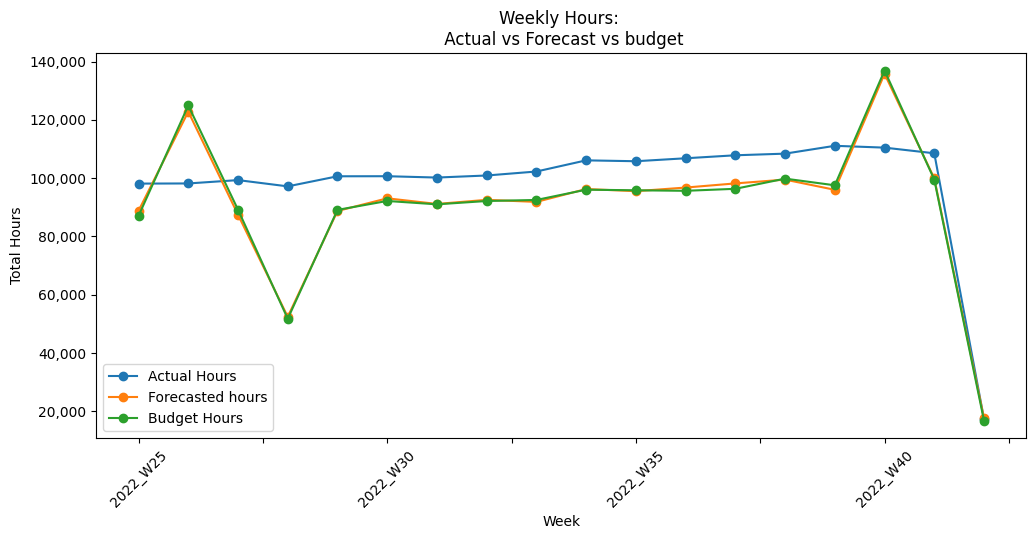

In [149]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

ax = weekly.plot(figsize=(12,5), marker='o', title='Weekly Hours: \n Actual vs Forecast vs budget')
ax.set_xlabel('Week')
ax.set_ylabel('Total Hours')
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f'{int(x):,}'))
plt.xticks(rotation=45)

plt.show()

The actual hours stay fairly steady from week to week (roughly 100k hours a week). The forecasted and budget lines jump in a couple of weeks (like week 26 and week 40), which is questionable because the actual hours do not jump with them (I need more information if I wanted to determine why that happened in more details, but by looking at the excel sheet it seems to come from a lot more rows in those weeks for the Switches department, so I think it is a data and numbers issue and not a real change in work/the company itself).

------------------------------------------------------------------------------

The reason I plotted this is that I wanted to see if the hours that the teams actually spent match what was forecasted and budgeted. Overall the actual hours are higher than both, which means projects are taking more time than orginally planned.

------------------------------------------------------------------------------
***Note:*** The drop at the very end (Week 42) is not a real drop, that week is only partially recorded, so I will treat it as an outlier later on.

### **Actual Hours By Department**

/tmp/ipykernel_3637/3074787727.py:12: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=90)


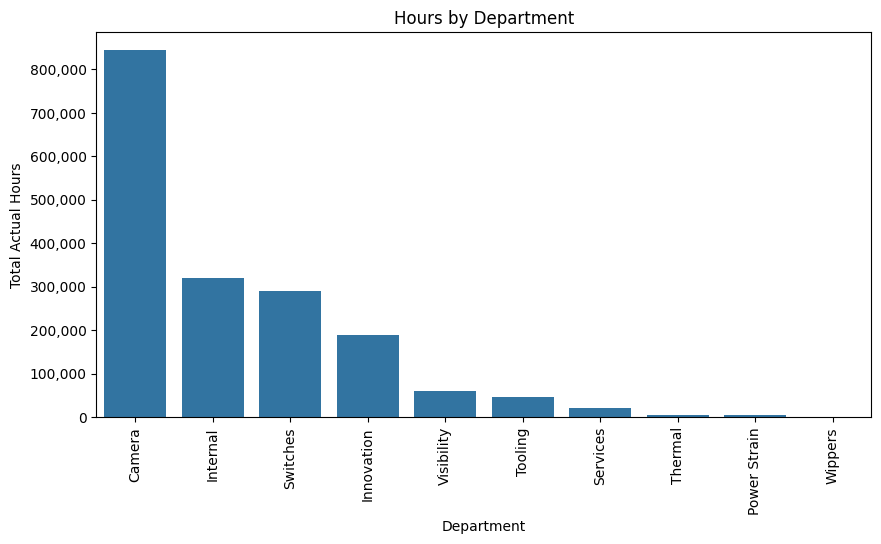

In [150]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

fmt = FuncFormatter(lambda x, _: f'{int(x):,}')

order = Projects_Hours.groupby('Department')['Actual Hours'].sum().sort_values(ascending=False).index

plt.figure(figsize=(10,5))
ax = sns.barplot(x='Department', y='Actual Hours', data=Projects_Hours, order=order, estimator=np.sum, errorbar=None)
ax.set_xticklabels(ax.get_xticklabels(), rotation=90)
ax.set_xlabel('Department')
ax.set_ylabel('Total Actual Hours')
ax.set_title('Hours by Department')
ax.yaxis.set_major_formatter(fmt)


plt.show()

Camera is by far the biggest department in terms of actual hours, with around 840k hours logged. Internal and Switches came next then Innovation. Departments like Thermal, Power Strain and Wippers are so small that you can barely see their bars.

---------------------------------------------------------------------------

I plotted this because I wanted to know where most of the work is happening, since that decides which departments matter most when looking at everything else later on.

### **Actual VS Budget Hours By Department**

/tmp/ipykernel_3637/4054523617.py:7: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=90)


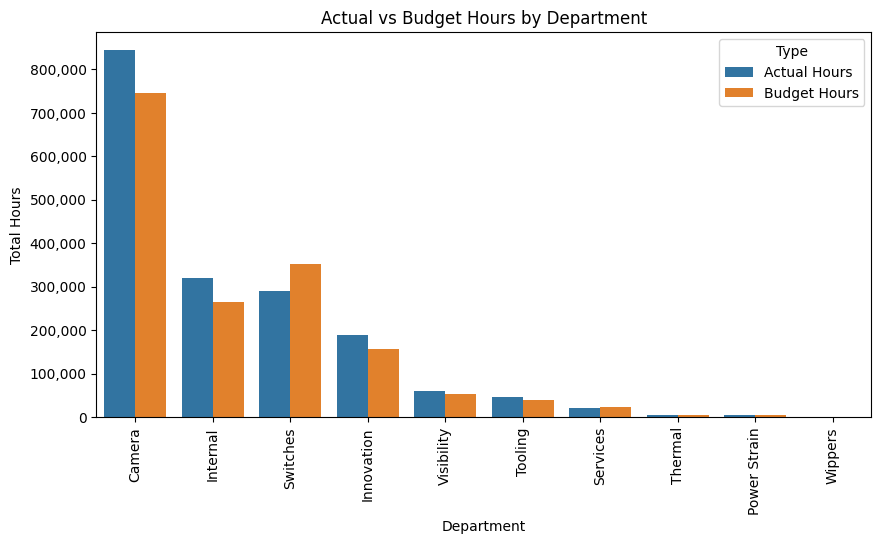

In [151]:
ab = (Projects_Hours.groupby('Department')[['Actual Hours', 'Budget Hours']].sum()
      .reset_index()
      .melt(id_vars='Department', var_name='Type', value_name='Hours'))

plt.figure(figsize=(10,5))
ax = sns.barplot(x='Department', y='Hours', hue='Type', data=ab, order=order)
ax.set_xticklabels(ax.get_xticklabels(), rotation=90)
ax.set_xlabel('Department')
ax.set_ylabel('Total Hours')
ax.set_title('Actual vs Budget Hours by Department')
ax.yaxis.set_major_formatter(fmt)


plt.show()

Most of the big departments spent more hours than they were budgeted. Camera is around 13% over, Internal and Innovation are around 20% over, and Tooling is about 22% over.

Switches and Services were the other way, they used fewer hours than budgeted (around 18% and 15% under). The small departments are hard to see in this graph because Camera had the most actual and budgeted hours, so the bar is long.

------------------------------------------------------------------------------

I plotted this To see which departments are planning well and which are not. Overall the actual hours are about 8% above budget, but this plot shows that it is not the same across all departments.

### **Hours By Project Status**

/tmp/ipykernel_3637/579723472.py:5: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=90)


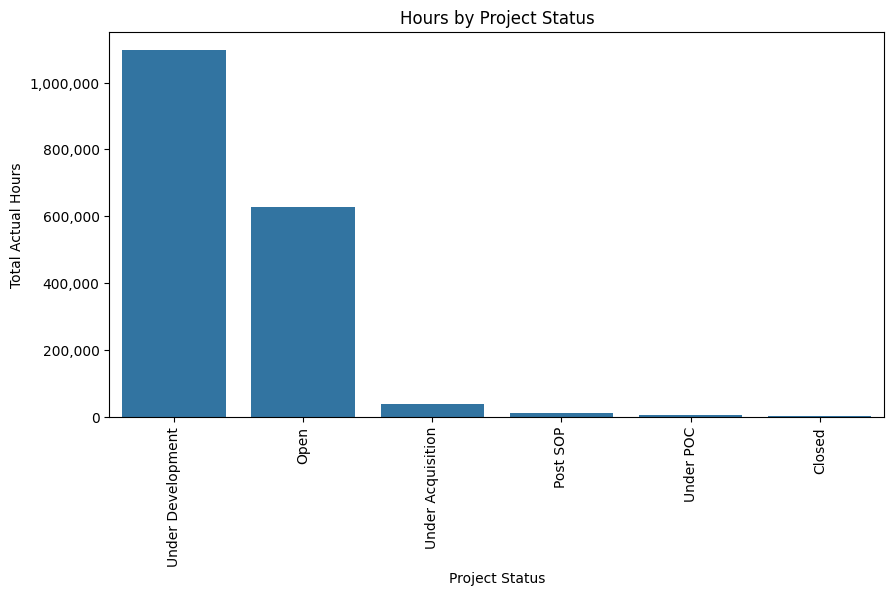

In [152]:
order_status = Projects_Hours.groupby('Project_Status')['Actual Hours'].sum().sort_values(ascending=False).index

plt.figure(figsize=(10,5))
ax = sns.barplot(x='Project_Status', y='Actual Hours', data=Projects_Hours, order=order_status, estimator=np.sum, errorbar=None)
ax.set_xticklabels(ax.get_xticklabels(), rotation=90)
ax.set_xlabel('Project Status')
ax.set_ylabel('Total Actual Hours')
ax.set_title('Hours by Project Status')
ax.yaxis.set_major_formatter(fmt)

plt.show()

Under Development has most of the hours (around 62%), followed by Open (around 35%). The sum of the other statuses (Under Acquisition, Post SOP, Under POC and Closed) is only around 3% of the hours, so their bars are not as visible as the other 2.

-------------------------------------------------------------------------------

I plotted this to see what stages that the work is done most in. It makes sense that most hours are in development and open projects and almost none are in closed ones.

## **Engineering Tickets**

### **Tickets Per Start Month**

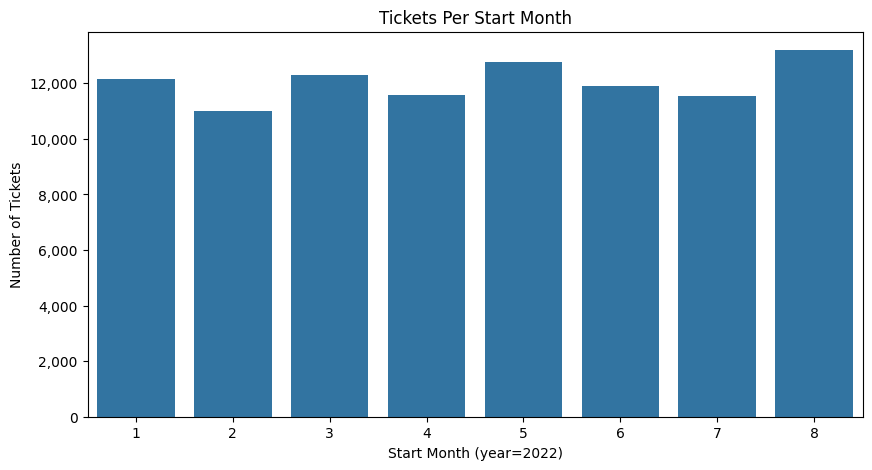

In [153]:
months = Engineering_Tickets['Start Date'].dt.month

plt.figure(figsize=(10,5))
ax = sns.countplot(x=months, order=sorted(months.unique()))
ax.set_xlabel('Start Month (year=2022)')
ax.set_ylabel('Number of Tickets')
ax.set_title('Tickets Per Start Month')
ax.yaxis.set_major_formatter(fmt)

plt.show()

The number of tickets started each month is pretty stable at around 11k to 13k. February is the lowest (about 11k) and August is the highest (about 13k). I don't see a clear upward or downward trend since the total number of tickets does not deviate that much between each month.

--------------------------------------------------------------------------------

I plotted this to check if the number of tickets is growing or if there are busy and quiet months. It looks like it is mostly flat, so there is no obvious trend or conclusion to be drawn.

### **Ticket Stage By Site**

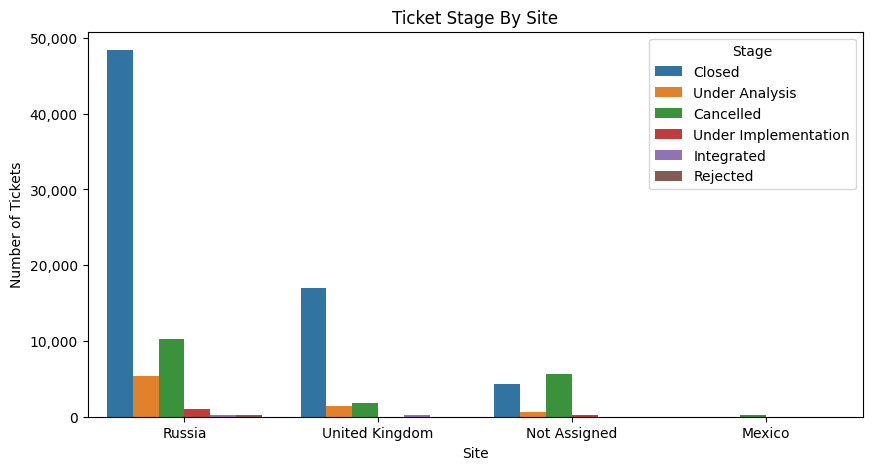

In [154]:
plt.figure(figsize=(10,5))
ax = sns.countplot(x='Site', hue='Stage', data=Engineering_Tickets, order=Engineering_Tickets['Site'].value_counts().index)

ax.set_xlabel('Site')
ax.set_ylabel('Number of Tickets')
ax.set_title('Ticket Stage By Site')
ax.yaxis.set_major_formatter(fmt)

plt.show()

Russia has most of the tickets (around 68%), then the United Kingdom (around 21%) and Not Assigned (around 11%). Mexico has very few tickets (192, that is why it is not that visisble on the bar chart) and all of them are cancelled. Around 74% of Russia's tickets are closed and around 84% of the UK's, while Not Assigned only has about 40% closed.

--------------------------------------------------------------------------------

I plotted this to compare how tickets are handled at each site. The Not Assigned tickets are closed much less often, which makes sense because nobody owns them and Mexico being 100% cancelled looks strange and I would have investigated it further if I had more information/data.

### **Tickets By Severity And Origin**

/tmp/ipykernel_3637/2752635170.py:5: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=90)


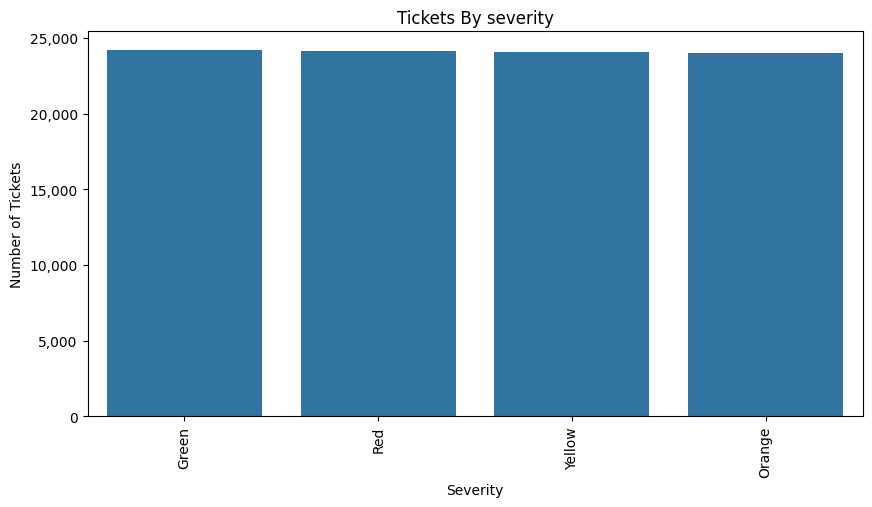

/tmp/ipykernel_3637/2752635170.py:5: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=90)


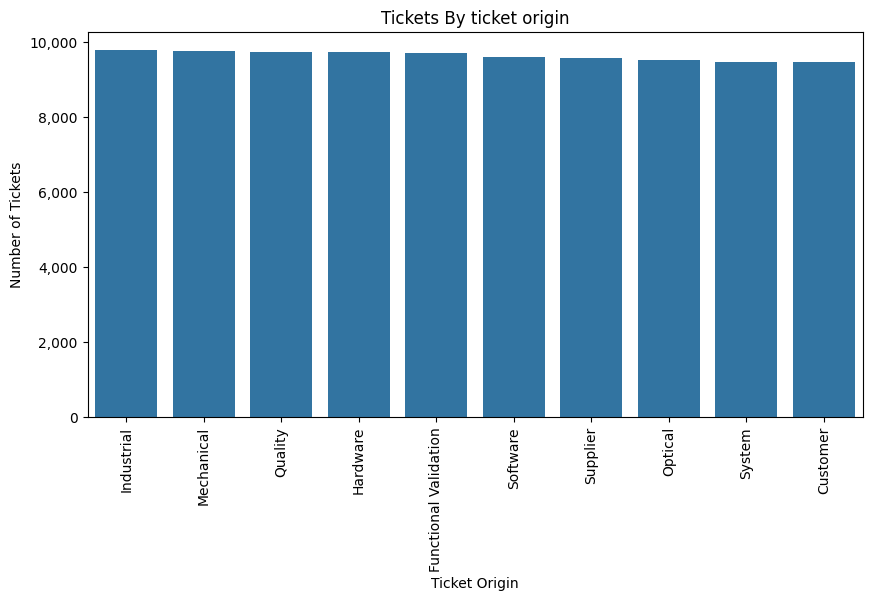

In [155]:
for col in ['Severity', 'Ticket Origin']:

    plt.figure(figsize=(10,5))
    ax = sns.countplot(x=col, data=Engineering_Tickets, order=Engineering_Tickets[col].value_counts().index)
    ax.set_xticklabels(ax.get_xticklabels(), rotation=90)
    ax.set_xlabel(col)
    ax.set_ylabel('Number of Tickets')
    ax.set_title(f'Tickets By {col.lower()}')
    ax.yaxis.set_major_formatter(fmt)

    plt.show()

***Tickets By Severity***


The four severity colours are almost perfectly equal, each is around 25% of the tickets (Green, Red, Yellow and Orange are all around 24k tickets).

--------------------------------------------------------------------------------

I plotted this to see if there are more serious (red) tickets than the others. There aren't, which is a bit unusual since I would have expected fewer red tickets than green ones, so I am not seeing a pattern here. I would need more information about the severity (policy) to be able to draw a conclusion.

***Tickets By Origin***

All 10 origins have about the same number of tickets (around 9.5k to 9.8k each, so about 10% each). Industrial is the highest and Customer is the lowest, but the difference is small.

------------------------------------------------------------------------------

I plotted this to see where the tickets come from. No single origin stands out as the main source of problems as they are almost equal.

## **Engineering Data**

### **Leave Hours By Department**

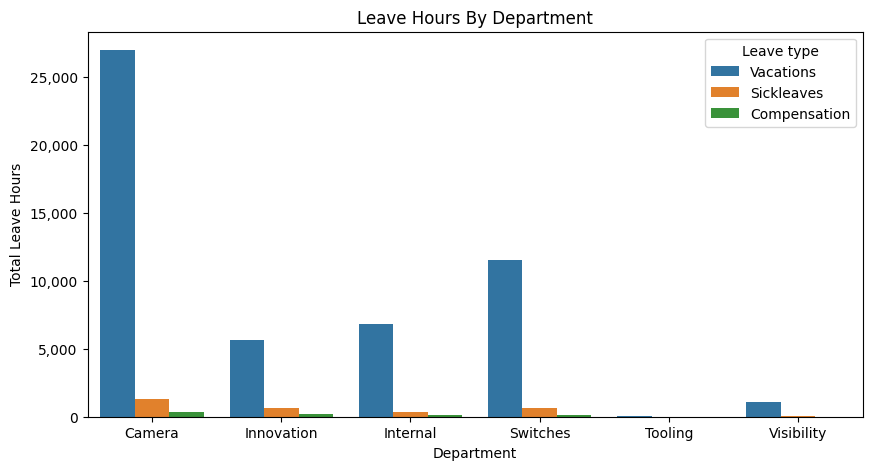

In [156]:
leave= (Engineering_Data.groupby('Department')[['Vacations', 'Sickleaves', 'Compensation']].sum()
         .reset_index()
         .melt(id_vars='Department', var_name='Leave type', value_name='Hours'))

plt.figure(figsize=(10,5))
ax = sns.barplot(x='Department', y='Hours', hue='Leave type', data=leave)
ax.set_xlabel('Department')
ax.set_ylabel('Total Leave Hours')
ax.set_title('Leave Hours By Department')
ax.yaxis.set_major_formatter(fmt)
plt.show()

Vacations are the biggest type of leave by far in every department and sick leave and compensation are very small in comparison. Camera has the highest totals but that is probably because it has the most engineers (its a huge departement that has around half of the total engineers working).

------------------------------------------------------------------------------

I plotted this to see how much time engineers are away and what for. I want to be careful with the totals though since big departments will always look bigger than the rest on charts, so the averages per engineer would be fairer.

### **Worked VS Theoretical Hours Per Engineer By Department**

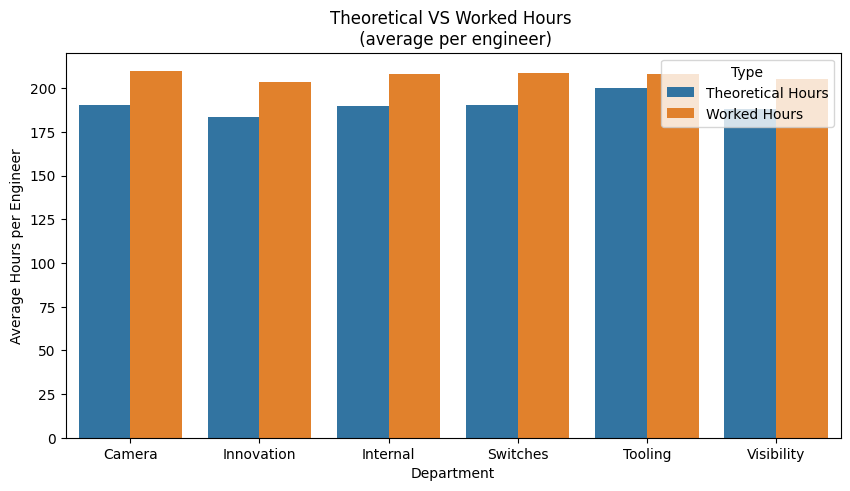

In [157]:
wt = (Engineering_Data.groupby('Department')[['Theoretical Hours', 'Worked Hours']].mean()
      .reset_index()
      .melt(id_vars='Department', var_name='Type', value_name='Average hours'))

plt.figure(figsize=(10,5))
ax = sns.barplot(x='Department', y='Average hours', hue='Type', data=wt)
ax.set_xlabel('Department')
ax.set_ylabel('Average Hours per Engineer')
ax.set_title('Theoretical VS Worked Hours \n (average per engineer)')
plt.show()

In every department the engineers worked more hours than they were expected to, with the average around 205 to 210 worked hours compared to almost 200 hours theoretical. The theoretical average looks a bit lower than 200 in some departments (around 190), which is because some engineers have 0 theoretical hours (I mentioned some of the reasons I think that may be above in the Data Cleaning section). Tooling only has one engineer, so its bars don't tell us much.

-----------------------------------------------------------------------------

I plotted this to check if engineers are overworked or underutilised. Most of them go a little over their expected hours, which is very questionable since as we mentioned projects take longer than ther forcasted and budgeted time (if this was an in real life scenario I would try to figure out what's the reason for their inefficiency despitethem working extended hours)

# **Outliers with Visualization**

In [158]:
Engineering_Data.loc[Engineering_Data['Holiday'] < 0, 'Holiday'] = 8
Engineering_Data['Total'] = Engineering_Data[['Vacations','Sickleaves','Compensation','Holiday']].sum(axis=1)

,Column,Lower limit,Upper limit,Outliers,% of rows
0,Actual Hours,-40.0,88.0,0,0.0
1,Forecasted hours,-20.0,60.0,0,0.0
2,Budget Hours,-20.0,60.0,0,0.0


,Column,Lower limit,Upper limit,Outliers,% of rows
0,Theoretical Hours,200.0,200.0,83,8.7
1,Worked Hours,182.5,242.5,103,10.8
2,Total,-32.0,160.0,8,0.8
3,Vacations,-40.0,152.0,4,0.4
4,Sickleaves,-6.0,10.0,57,6.0
5,Compensation,0.0,0.0,61,6.4
6,Holiday,8.0,8.0,2,0.2


/tmp/ipykernel_3637/4139774956.py:17: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=90)


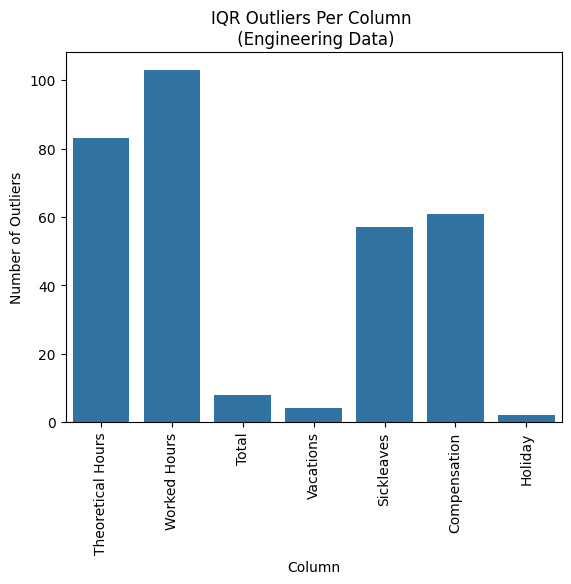

In [159]:
def iqr_table(df, cols):
    rows = []
    for col in cols:
        q1, q3 = df[col].quantile(0.25), df[col].quantile(0.75)
        iqr = q3 - q1
        low, high = q1 - 1.5*iqr, q3 + 1.5*iqr
        n = ((df[col] < low) | (df[col] > high)).sum()
        rows.append([col, low, high, n, round(n / len(df) * 100, 1)])
    return pd.DataFrame(rows, columns=['Column', 'Lower limit', 'Upper limit', 'Outliers', '% of rows'])

display(iqr_table(Projects_Hours, ['Actual Hours', 'Forecasted hours', 'Budget Hours']))
display(iqr_table(Engineering_Data, ['Theoretical Hours', 'Worked Hours', 'Total', 'Vacations', 'Sickleaves', 'Compensation', 'Holiday']))


t = iqr_table(Engineering_Data, ['Theoretical Hours', 'Worked Hours', 'Total', 'Vacations', 'Sickleaves', 'Compensation', 'Holiday'])
ax = sns.barplot(x='Column', y='Outliers', data=t)
ax.set_xticklabels(ax.get_xticklabels(), rotation=90)
ax.set_ylabel('Number of Outliers')
ax.set_title('IQR Outliers Per Column \n (Engineering Data)')

plt.show()

This table shows, for each column, the limits of the IQR rule and how many values fall outside them. Actual, Forecasted and Budget Hours have none, while Worked Hours has the most (almost 11% of engineers).

The graph shows the same numbers as the table, so it is easier to see which columns have the most outliers. Keep in mind that for Theoretical Hours, Compensation and Holiday the count isn't really meaningful, since almost everyone has the same value (which can be seen here and in the Trends and Patterns section above) and the rule flags anything different.

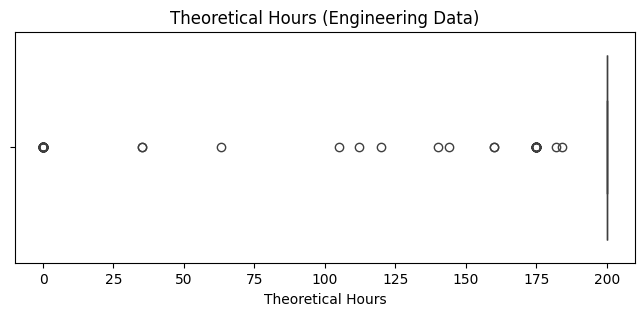

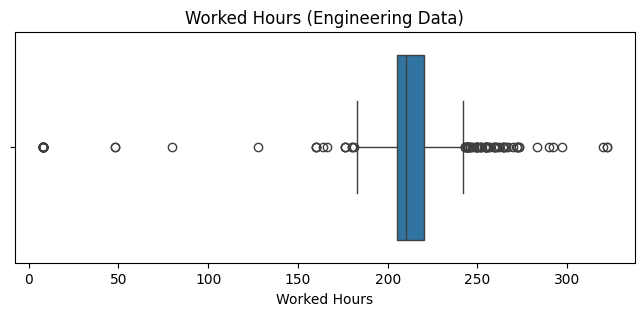

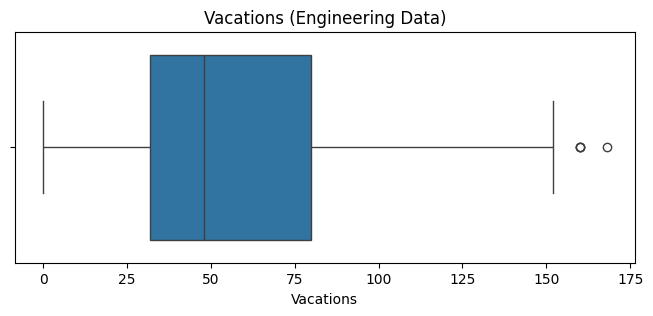

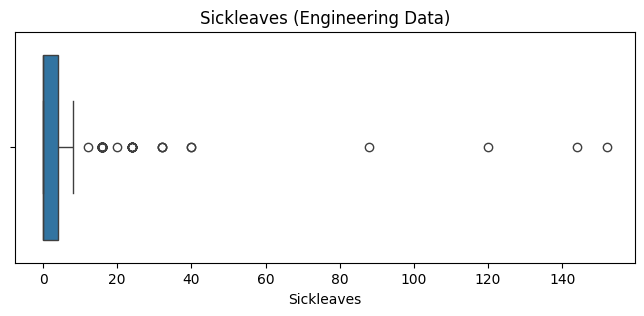

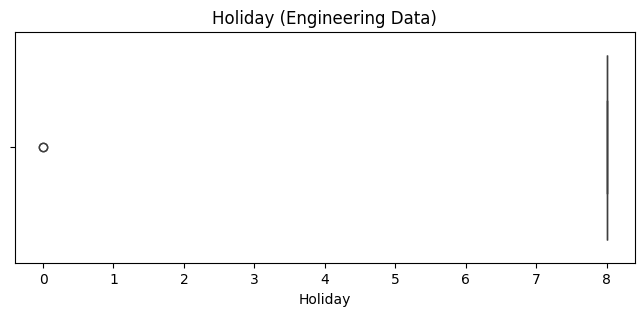

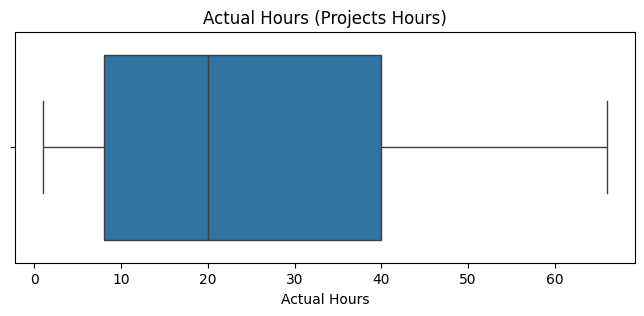

In [160]:
for col in ['Theoretical Hours', 'Worked Hours', 'Vacations', 'Sickleaves', 'Holiday']:
    plt.figure(figsize=(8,3))
    sns.boxplot(x=Engineering_Data[col])
    plt.title(f'{col} (Engineering Data)')
    plt.show()

plt.figure(figsize=(8,3))
sns.boxplot(x=Projects_Hours['Actual Hours'])
plt.title('Actual Hours (Projects Hours)')
plt.show()

I used boxplots and the IQR rule. Actual, Forecasted and Budget Hours have no outliers. In Engineering Data --> Theoretical Hours, Compensation and Holiday have an IQR of 0 (almost everyone has the same value), so the rule flags anything different, which isn't really meaningful. Worked Hours has outliers on both sides: very high values (up to 322, probably overtime) and very low ones (like 8, probably engineers who joined or left during the month), I kept all of them since the data looked real and logically it made sense.

The only value I changed was the Holiday of -48, because a negative number of holidays is impossible, so I replaced it with 8 (the most common value). Orginally I thought maybe that employee did not take any holidays for like years, so that's why its in negative, but I realized that was wrong since no other employee has their number in negative, so this is just an error and an outlier that would skew the graphs downwards if not fixed. By the way I noticed the -48 very early on in the Data Inspection section since I could see in the output all the unique values in each column (but I did not fix it in th data cleaning because in my opinion it acts more as an outlier since its not a missig value or a duplicate, its an actual valid record with just 1 value wrong in 1 column).

(I ran the IQR table above after replacing the -48, so Holiday shows 2 outliers instead of 3.)

# **KPIs Identification**

These are the KPIs I chose to summarise each dataset. I picked ones that answer each of the following business questions *Are we on plan? Are our tickets getting resolved? Are the engineers fully utilized?* (things that I can calculate from the columns/attributes that I have).

<div style="font-size:20px;">

| **KPI** | **Dataset** | **How I calculate it** | **Why it matters** |
|---------|-------------|------------------------|--------------------|
| **Total Actual Hours** | Projects Hours | Sum of Actual Hours | Shows the total amount of work logged. |
| **Budget Variance %** | Projects Hours | (Total Actual Hours / Total Budget Hours - 1) x 100 | Shows if projects take more or less time than budgeted (positive means over budget). |
| **Forecast Error %** | Projects Hours | Sum of \|Actual - Forecast\| per project / Total Actual Hours x 100 | Shows how far off the forecasts are (lower is better). |
| **% of Projects Over Budget** | Projects Hours | Projects with Actual > Budget / Total projects x 100 | Shows how common budget overruns are. |
| **Closure Rate** | Engineering Tickets | Closed tickets / Total tickets x 100 | Shows how many tickets get resolved. |
| **Cancellation Rate** | Engineering Tickets | Cancelled tickets / Total tickets x 100 | Shows how many tickets are dropped. |
| **Open Backlog** | Engineering Tickets | Tickets that are Under Analysis or Under Implementation | Shows the work still in progress. |
| **Utilisation %** | Engineering Data | Total Worked Hours / Total Theoretical Hours x 100 (without engineers with 0 theoretical hours) | Shows if engineers work more or less than expected. |
| **Sick Leave Rate %** | Engineering Data | Total Sickleaves / Total Theoretical Hours x 100 | Shows how much time is lost to sickness. |

</div>

In [161]:
# Projects Hours
total_actual = Projects_Hours['Actual Hours'].sum()
total_budget = Projects_Hours['Budget Hours'].sum()
budget_variance = (total_actual / total_budget - 1) * 100

proj = Projects_Hours.groupby('Project Code')[['Actual Hours', 'Forecasted hours', 'Budget Hours']].sum()
forecast_error = (proj['Actual Hours'] - proj['Forecasted hours']).abs().sum() / proj['Actual Hours'].sum() * 100
pct_over_budget = (proj['Actual Hours'] > proj['Budget Hours']).mean() * 100

# Engineering Tickets
n_tickets = len(Engineering_Tickets)
closure_rate = (Engineering_Tickets['Stage'] == 'Closed').sum() / n_tickets * 100
cancel_rate = (Engineering_Tickets['Stage'] == 'Cancelled').sum() / n_tickets * 100
open_backlog = Engineering_Tickets['Stage'].isin(['Under Analysis', 'Under Implementation']).sum()

# Engineering Data (leaving out the engineers with 0 theoretical hours)
eng = Engineering_Data[Engineering_Data['Theoretical Hours'] > 0]
utilisation = eng['Worked Hours'].sum() / eng['Theoretical Hours'].sum() * 100
sick_rate = eng['Sickleaves'].sum() / eng['Theoretical Hours'].sum() * 100

kpis = pd.DataFrame({
    'KPI': ['Total Actual Hours', 'Budget Variance %', 'Forecast Error %', '% of Projects Over Budget',
            'Closure Rate %', 'Cancellation Rate %', 'Open Backlog (tickets)', 'Utilisation %', 'Sick Leave Rate %'],
    'Value': [f'{total_actual:,}', round(budget_variance, 1), round(forecast_error, 1), round(pct_over_budget, 1),
              round(closure_rate, 1), round(cancel_rate, 1), f'{open_backlog:,}', round(utilisation, 1), round(sick_rate, 1)]
})
display(kpis)

,KPI,Value
0,Total Actual Hours,"1,779,701"
1,Budget Variance %,8.2
2,Forecast Error %,24.8
3,% of Projects Over Budget,56.4
4,Closure Rate %,72.2
5,Cancellation Rate %,18.4
6,Open Backlog (tickets),"8,492"
7,Utilisation %,108.4
8,Sick Leave Rate %,1.6


The KPIs show that the projects are taking 8.2% more hours than budgeted (56.4% of projects went over budget), and the forecasts are off by about 24.8% on average, so the planning is not very accurate.

For the tickets, about 72.2% are closed and 18.4% are cancelled, with around 8.492 tickets still open.

Engineers worked about 8.4% more than their expected hours (utilisation of 108.4%), which means they are doing overtime, while sick leave is low (1.6% of the expected hours).

# **Linking The 3 Datasets**

In [162]:
proj = Projects_Hours.groupby('Project Code').agg(
    Dept=('Department', 'first'),
    Actual=('Actual Hours', 'sum'),
    Forecast=('Forecasted hours', 'sum'),
    Budget=('Budget Hours', 'sum')).reset_index()

linked = Engineering_Tickets.merge(proj, on='Project Code', how='left')

print(linked.shape)
print(linked['Dept'].isna().sum())

#Project Code is the link between tickets and hours. I grouped Projects Hours by project first because a project has many rows, so joining directly would repeat each ticket.
#I checked that every ticket matched a project (0 unmatched)



names = (Engineering_Data.groupby('Name')['Department']
         .agg(lambda s: s.iloc[0] if s.nunique() == 1 else 'Ambiguous')
         .reset_index()
         .rename(columns={'Name': 'Current Assignee', 'Department': 'Assignee Dept'}))

linked = linked.merge(names, on='Current Assignee', how='left')
linked['Assignee Dept'] = linked['Assignee Dept'].fillna('Unassigned')

print(linked.shape)
print(linked['Assignee Dept'].value_counts())

#Names that appear twice with different departments are labelled Ambiguous, since I can not tell which person the ticket belongs to. I have mentioned this issue in more details in the Data Cleaning section (Engineer Data Sheet)



hours_dept = Projects_Hours.groupby('Department')['Actual Hours'].sum()
tix_dept = linked.groupby('Dept').size()
eng_dept = Engineering_Data[Engineering_Data['Theoretical Hours'] > 0].groupby('Department').agg(
    Engineers=('Name', 'count'), Worked=('Worked Hours', 'sum'))

dept = pd.DataFrame({'Actual Hours': hours_dept, 'Tickets': tix_dept}).join(eng_dept)
dept['Tickets per 1000 hours'] = (dept['Tickets'] / dept['Actual Hours'] * 1000).round(1)
dept['Weekly hours logged vs capacity'] = ((dept['Actual Hours'] / Projects_Hours['Week'].nunique()) / (dept['Worked'] / 4.35)).round(1)

display(dept)


(96428, 13)
0
(96428, 14)
Assignee Dept
Camera        48475
Switches      21196
Internal      13270
Innovation    10142
Visibility     1714
Ambiguous       837
Unassigned      682
Tooling         112
Name: count, dtype: int64


,Actual Hours,Tickets,Engineers,Worked,Tickets per 1000 hours,Weekly hours logged vs capacity
Camera,843396,11215,464.0,100049.0,13.3,2.0
Innovation,189356,15624,96.0,20702.0,82.5,2.2
Internal,319622,18953,127.0,27057.0,59.3,2.9
Power Strain,5202,2768,NaN,NaN,532.1,NaN
Services,20021,8700,NaN,NaN,434.5,NaN
Switches,289232,4076,205.0,43800.0,14.1,1.6
Thermal,5657,1718,NaN,NaN,303.7,NaN
Tooling,47181,16797,1.0,208.0,356.0,54.8
Visibility,59933,16559,16.0,3485.0,276.3,4.2
Wippers,101,18,NaN,NaN,178.2,NaN


**Insight 1: Tickets don't follow hours.** Camera has the most hours (843,396) but only 11,215 tickets, which is 13 tickets per 1000 hours. Switches is similar (289,232 hours and 4,076 tickets). On the other hand, Tooling, Visibility, Services and Power Strain have much fewer hours, but a lot of tickets (between 276 and 532 tickets per 1000 hours). Tooling has 16,797 tickets with only 47,181 hours. So the number of hours logged isn't a good indicator of how many tickets a department has.

**Insight 2: The engineer file doesn't cover everyone.** Services, Power Strain, Thermal and Wippers have hours and tickets but no engineers at all in Engineering Data and Tooling has just 1 engineer (which is why its ratio of 54.8 is meaningless). For the other departments, the hours logged on projects are 1.6 to 4.2 times higher than the worked hours of the engineers in the file, so the file probably only covers part of the people or a different period (October only, maybe some employees work part time and did not work on October? Maybe some work cross-departements, but their names are only noted in one departement becuase there is no a 'cross-departements' option on the sytem? This really depeneds on the company and the scenario, so I would need more information to draw a consclusion). By the way this I also knew early one because of the Data Inspection section, I compared the departements listed in the output in both the Projects Hours sheet and the Engineering Data sheet and found ou that some were missing.

**Insight 3: Tickets are handled by other departments.** Camera engineers are assigned 48,475 tickets and Switches engineers 21,196, which is far more than the tickets that come from Camera (11,215) and Switches (4,076) projects. So they must be handling tickets from other departments' projects too. This looks like the tickets' assignment follows headcount (Camera has the most engineers therefore, they are assigned the most tickets to solve), not the department in charge of the project (which again may be linked to my cross-departements employees theory in Insight 2).

# **Exporting For Data Studio**

In [163]:
from google.colab import files

Projects_Hours.to_csv('projects_hours_clean.csv', index=False)
linked.to_csv('tickets_linked_clean.csv', index=False)
Engineering_Data.to_csv('engineering_data_clean.csv', index=False)
dept.reset_index().rename(columns={'index': 'Department'}).to_csv('department_summary.csv', index=False)

for f in ['projects_hours_clean.csv', 'tickets_linked_clean.csv', 'engineering_data_clean.csv', 'department_summary.csv']:
    files.download(f)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>